### **Student Information**
GitHub ID: VictorXieGit

Kaggle name:victorxieemlyon

Kaggle private scoreboard snapshot: Could not submit

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development

**Pipeline, start to end:** join the three competition files → look at class balance and post length → hold out 20% of the training posts for comparing models (the Kaggle test labels are hidden) → compare representations from the Master (TF-IDF) with pretrained ones → fine-tune the best pretrained model → retrain it on all training posts → predict the 1,440 test posts → `submission.csv`.

| Model | Representation | Validation macro F1 (672 posts) |
|---|---|---|
| Master's best | TF-IDF unigrams + LinearSVC | 0.483 |
| Master's idea, extended | TF-IDF word 1–2-grams + char 2–5-grams + LinearSVC | 0.549 |
| Pretrained, no training | emotion DistilRoBERTa, zero-shot | 0.577 |
| Pretrained features | its 7 emotion scores + LogisticRegression | 0.597 |
| **Final** | **emotion DistilRoBERTa, fine-tuned on our labels** | **0.626** |

The baseline to beat is 0.5; only the fine-tuned model clears 0.6.

### 1.1 Preprocessing Steps

* **Joining the files:** `final_posts.json` (post text) + `data_identification.csv` (train/test) + `emotion.csv` (labels for train only) are merged on `post_id`: 3,360 training posts, 1,440 test posts, no missing text.
* **What the data looks like:** six emotions, unbalanced: joy 875, anger 674, sadness 628, disgust 454, surprise 441, fear 288. Posts are short (median 13 words, 95% under 33), so a 128-token limit for the transformer cuts almost nothing. 50 training texts appear twice; they are kept, as in Master Exercise 1.
* **Two cleanings for two kinds of model:**
    * for TF-IDF: lowercase, links → `url`, usernames → `user`, `soooo` → `soo` (the Master's cleaning plus placeholders);
    * for the transformer: **no cleaning.** Its tokenizer was trained on raw text, and capitals, punctuation and emoji carry emotion.
* **Validation split:** one stratified 80/20 split of the training posts (2,688 / 672), fixed seed. It is used only to compare models, never to train the submitted model. This replaces the Master's dev set, since Kaggle's test labels are hidden.

### 1.2 Feature Engineering Steps

* **TF-IDF (from the Master):** unigrams first, then word 1–2-grams + character 2–5-grams with `sublinear_tf`. The character features add +0.066, but TF-IDF stays far below what it reached in the Master (0.862). The Master's tweets were collected by searching for emotion words, so the label word was usually in the text; these posts rarely name their emotion ("Bear died in a pit", "I have endured worse."), so word counts are not enough.
* **Pretrained emotion scores:** `j-hartmann/emotion-english-distilroberta-base` is a DistilRoBERTa already trained by its authors on ~20k English emotion sentences, with 7 outputs: our 6 emotions + *neutral*. Used zero-shot (ignoring *neutral*) it already beats every TF-IDF model; its 7 log-probabilities as features for a logistic regression give 0.597.
* **Tried and dropped:** general sentence embeddings (all-MiniLM-L6-v2 like the Master's MiniLM, and all-mpnet-base-v2) + logistic regression scored 0.47–0.49 in 5-fold cross-validation, below TF-IDF. Embeddings trained for meaning similarity do not separate emotions well, the same lesson as Master 6.4, where MiniLM lost to TF-IDF for classification.

### 1.3 Explanation of Your Model

* **Fine-tuning:** the pretrained emotion model's 7-way output layer is replaced by a new 6-way layer, and **all** its weights are trained on our labels: 3 epochs, AdamW, learning rate 3e-5 with 10% warm-up then linear decay, batch 16, gradient clipping at 1.0, max 128 tokens. This keeps everything the model already knows about emotional language and adapts it to this dataset's posts and labels. It ran on a laptop-class CPU in about 9 minutes (12 for the final training on all posts).
* **Validation result:** 0.617 → 0.634 → 0.626 macro F1 after epochs 1, 2, 3. The epoch-to-epoch changes (under 0.01, about 5 posts out of 672) are noise, so I kept the planned 3 epochs instead of picking the best epoch on the validation set (the lesson of AgentPipeline Exercise 14).
* **Errors:** joy is easiest (F1 0.78); **disgust is hardest (F1 0.45, recall 0.40)**: its errors spread over every class, the largest being 18 disgust posts predicted as anger. Adding both directions (18 + 15 = 33), **anger ↔ disgust is the most confused pair**, ahead of anger ↔ joy (22). It plays the role anger ↔ fear played in Master Exercise 8: two hostile reactions that share much of the same vocabulary.
* **Submission:** the same recipe is retrained on all 3,360 training posts (no setting is chosen any more), then predicts the 1,440 test posts. The predicted class mix (joy 374, anger 335, sadness 278, surprise 198, disgust 157, fear 98) follows the training distribution.

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

I used Claude (an AI coding assistant) for this part. My prompts:

> *"Let's do the third part which is a Kaggle competition … Try to implement a first model with the ideas we had in the master notebook "*

| AI suggestion | Decision | Why |
|---|---|---|
| Start from the Master's TF-IDF + LinearSVC, then add bigrams and character n-grams | **Adopted as baselines** | Measures how far the Master's approach goes here (0.483 → 0.549); both stay under 0.6. |
| Use sentence embeddings (MiniLM, mpnet) as in Master Section 5 | **Rejected** | 0.47–0.49 in cross-validation, below TF-IDF. |
| Use a pretrained *emotion* model, first zero-shot, then as features | **Adopted as a step** | Beats TF-IDF without training (0.577), confirming pretrained emotion knowledge is the missing ingredient. |
| Fine-tune that emotion model on the competition labels | **Adopted (final model)** | Best validation score (0.626) and runs on CPU, so no GPU or Colab was needed. |
| Compare models on a held-out 20% only, retrain on everything at the end | **Adopted** | Kaggle's test labels are hidden; this keeps model choice off the test set, as in Exercise 14. |
| Choose the number of epochs from the validation curve | **Rejected** | The differences between epochs are within noise; picking the best one would overstate the score. |

Every number in this report is printed by the code below.

---


**`From here on starts the code section for the competition.`**

---

# **Competition Code**

The competition files are expected in `2026-dm-lab-2-private-competition/` at the repository root (downloaded from Kaggle; not committed, since the repository is public). The whole notebook runs on CPU in the lab's `uv` environment; the two fine-tuning cells take about 10–15 minutes each on a laptop CPU, or about 1 minute on a Colab/Kaggle GPU.

## 1. Preprocessing Steps

In [ ]:
# Imports for the whole pipeline.
import json, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.special import softmax
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

SEED = 42
DATA = "2026-dm-lab-2-private-competition"
LABELS = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]   # the 6 competition classes
torch.manual_seed(SEED)

/tmp/claude-0/-home-user-DM2026-Lab2-Exercise/d140be90-33ea-511f-a0bd-38e730f6ff9f/scratchpad/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Join the three files: post text + which split it belongs to + its label (train only).
posts = pd.DataFrame(json.load(open(f"{DATA}/final_posts.json")))           # post_id, text
split = pd.read_csv(f"{DATA}/data_identification.csv")                       # post_id, set
labels = pd.read_csv(f"{DATA}/emotion.csv")                                  # post_id, label
df = split.merge(posts, on="post_id").merge(labels, on="post_id", how="left")

train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df = df[df["set"] == "test"].reset_index(drop=True)
print("train:", train_df.shape, "| test:", test_df.shape)
print("missing text:", df["text"].isna().sum(), "| duplicated text in train:", train_df["text"].duplicated().sum())

train: (3360, 4) | test: (1440, 4)
missing text: 0 | duplicated text in train: 50


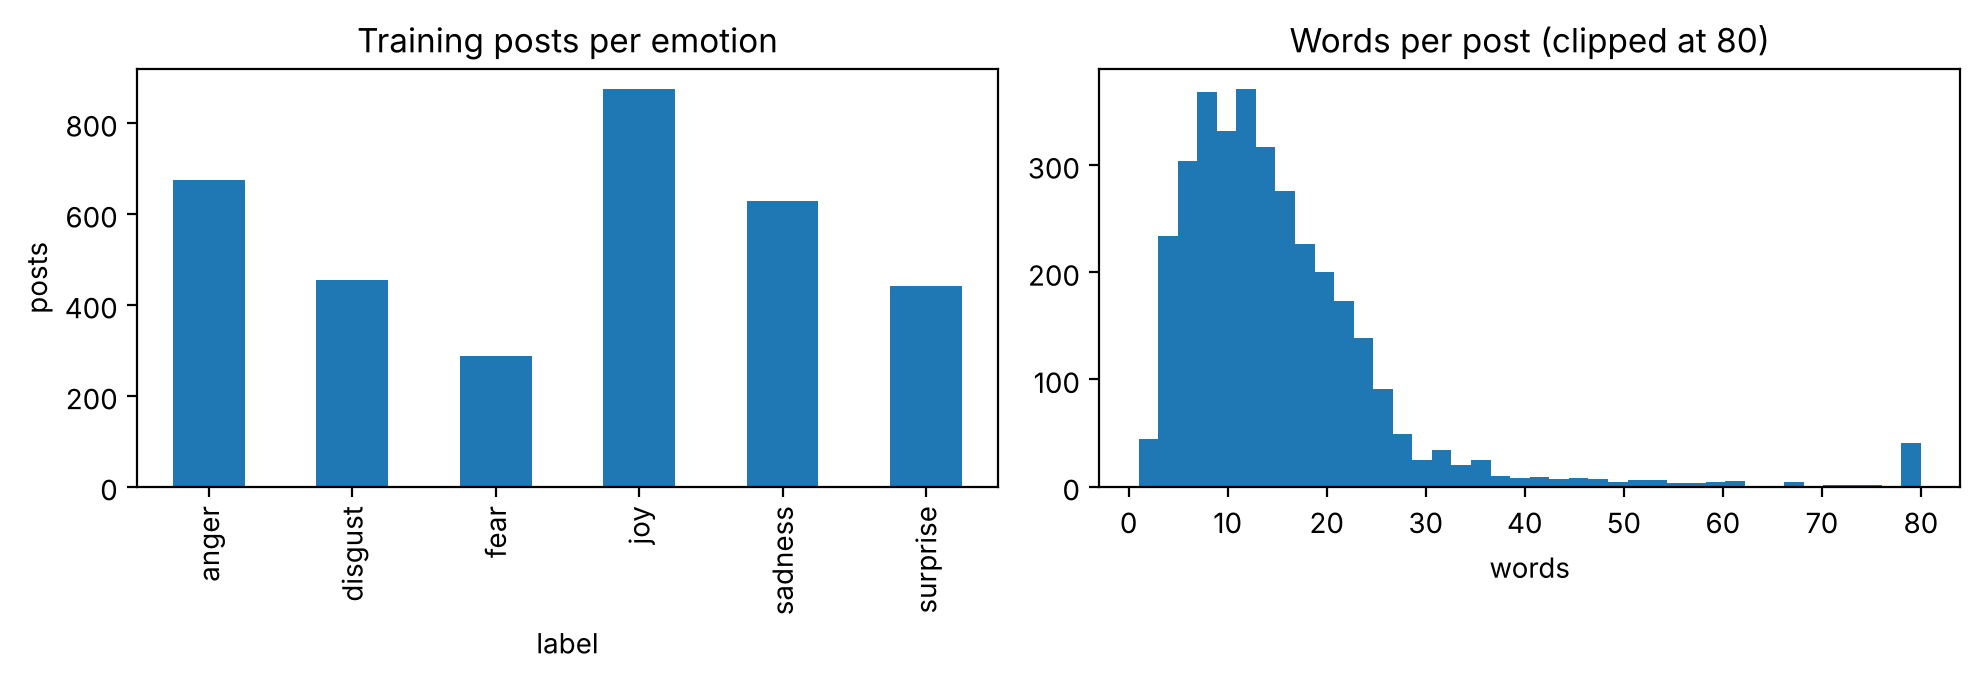

{'anger': 674, 'disgust': 454, 'fear': 288, 'joy': 875, 'sadness': 628, 'surprise': 441}
median words: 13.0 | 95th percentile: 33.0


In [ ]:
# Class balance and post length: the two facts that decide the metric and the model.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
train_df["label"].value_counts().reindex(LABELS).plot.bar(ax=axes[0])
axes[0].set_title("Training posts per emotion"); axes[0].set_ylabel("posts")
words = train_df["text"].str.split().str.len()
axes[1].hist(words.clip(upper=80), bins=40)
axes[1].set_title("Words per post (clipped at 80)"); axes[1].set_xlabel("words")
plt.tight_layout(); plt.show()
print(train_df["label"].value_counts().reindex(LABELS).to_dict())
print("median words:", words.median(), "| 95th percentile:", words.quantile(0.95))

In [ ]:
# Cleaning for the TF-IDF models only. The transformer gets the raw text:
# its own tokenizer was trained on raw text, and capitals/punctuation carry emotion.
def clean_text(s: str) -> str:
    s = s.lower()
    s = re.sub(r"http\S+|www\.\S+", " url ", s)    # links -> placeholder
    s = re.sub(r"/?u/\w+|@\w+", " user ", s)         # usernames -> placeholder
    s = re.sub(r"(.)\1{2,}", r"\1\1", s)            # soooo -> soo
    return re.sub(r"\s+", " ", s).strip()

for d in (train_df, test_df):
    d["clean"] = d["text"].map(clean_text)

# One held-out 20% of the training posts, stratified, used ONLY to compare models.
# The Kaggle test labels are hidden, so this split plays the role of the Master's dev set.
fit_df, val_df = train_test_split(train_df, test_size=0.2, stratify=train_df["label"], random_state=SEED)
print("fit:", len(fit_df), "| validation:", len(val_df))
score = lambda pred: round(f1_score(val_df["label"], pred, average="macro"), 4)

fit: 2688 | validation: 672


## 2. Feature Engineering Steps

In [ ]:
# Features 1: TF-IDF (the Master's representation), unigrams vs. word 1-2-grams + char 2-5-grams.
results = []
uni = Pipeline([("tfidf", TfidfVectorizer(min_df=2)), ("clf", LinearSVC(random_state=SEED))])
uni.fit(fit_df["clean"], fit_df["label"])
results.append({"model": "TF-IDF unigrams + LinearSVC (Master's best)", "val macro F1": score(uni.predict(val_df["clean"]))})

word_char = FeatureUnion([
    ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
])
wc = Pipeline([("feats", word_char), ("clf", LinearSVC(C=0.1, class_weight="balanced", random_state=SEED))])
wc.fit(fit_df["clean"], fit_df["label"])
results.append({"model": "TF-IDF word+char + LinearSVC", "val macro F1": score(wc.predict(val_df["clean"]))})
pd.DataFrame(results)

,model,val macro F1
0,TF-IDF unigrams + LinearSVC (Master's best),0.4828
1,TF-IDF word+char + LinearSVC,0.5485


In [ ]:
# Features 2: a pretrained emotion classifier (DistilRoBERTa fine-tuned on ~20k emotion
# sentences by its authors) has 7 outputs: our 6 emotions + "neutral". Its scores are
# used (a) directly, zero-shot, and (b) as 7 features for a logistic regression.
MODEL = "j-hartmann/emotion-english-distilroberta-base"
tok = AutoTokenizer.from_pretrained(MODEL)
pre = AutoModelForSequenceClassification.from_pretrained(MODEL).eval()
PRE_LABELS = [pre.config.id2label[i] for i in range(pre.config.num_labels)]

def emotion_scores(texts, model, bs=64):
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), bs):
            b = tok(list(texts[i:i + bs]), padding=True, truncation=True, max_length=128, return_tensors="pt")
            out.append(torch.log_softmax(model(**b).logits, -1).numpy())
    return np.vstack(out)

t0 = time.time()
S_fit, S_val = emotion_scores(fit_df["text"].tolist(), pre), emotion_scores(val_df["text"].tolist(), pre)
print(f"scored {len(fit_df) + len(val_df)} posts in {time.time() - t0:.0f}s; outputs: {PRE_LABELS}")

keep = [PRE_LABELS.index(l) for l in LABELS]                     # drop "neutral" for zero-shot
zero_shot = np.array(LABELS)[S_val[:, keep].argmax(1)]
results.append({"model": "Pretrained emotion model, zero-shot", "val macro F1": score(zero_shot)})

stack = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=3000, class_weight="balanced"))
stack.fit(S_fit, fit_df["label"])
results.append({"model": "Pretrained emotion scores + LogisticRegression", "val macro F1": score(stack.predict(S_val))})
pd.DataFrame(results)


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 105/105 [00:00<00:00, 8714.62it/s]

scored 3360 posts in 80s; outputs: ['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']


,model,val macro F1
0,TF-IDF unigrams + LinearSVC (Master's best),0.4828
1,TF-IDF word+char + LinearSVC,0.5485
2,"Pretrained emotion model, zero-shot",0.5772
3,Pretrained emotion scores + LogisticRegression,0.5970


## 3. Model Implementation Steps

In [ ]:
# Final model: fine-tune the whole pretrained emotion model on the competition labels.
# Its 7-way output layer is replaced by a fresh 6-way layer; all weights are then trained.
def fine_tune(train_part, epochs=3, lr=3e-5, bs=16, eval_part=None):
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL, num_labels=len(LABELS), ignore_mismatched_sizes=True,
        id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)})
    y = torch.tensor(train_part["label"].map(LABELS.index).values)
    texts = train_part["text"].tolist()
    steps = epochs * int(np.ceil(len(texts) / bs))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)   # 10% warm-up, then linear decay
    rng = np.random.RandomState(SEED)
    for ep in range(epochs):
        model.train()
        order = rng.permutation(len(texts))
        for i in range(0, len(order), bs):
            idx = order[i:i + bs]
            b = tok([texts[j] for j in idx], padding=True, truncation=True, max_length=128, return_tensors="pt")
            loss = model(**b, labels=y[idx]).loss
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
        model.eval()
        if eval_part is not None:
            pred = np.array(LABELS)[emotion_scores(eval_part["text"].tolist(), model).argmax(1)]
            print(f"epoch {ep + 1}: validation macro F1 {score(pred)}")
    return model

t0 = time.time()
ft_val_model = fine_tune(fit_df, eval_part=val_df)     # trained on 80%, checked on the 20%
print(f"fine-tuning took {(time.time() - t0) / 60:.1f} min")
ft_val_pred = np.array(LABELS)[emotion_scores(val_df["text"].tolist(), ft_val_model).argmax(1)]
results.append({"model": "Fine-tuned emotion DistilRoBERTa (final)", "val macro F1": score(ft_val_pred)})
pd.DataFrame(results)

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `7`.



Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 105/105 [00:00<00:00, 11503.55it/s]


[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                        | Status   |                                                                                       
---------------------------+----------+---------------------------------------------------------------------------------------
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([6])          
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 768]) vs model:torch.Size([6, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


epoch 1: validation macro F1 0.6171


epoch 2: validation macro F1 0.6341


epoch 3: validation macro F1 0.6258
fine-tuning took 9.2 min


,model,val macro F1
0,TF-IDF unigrams + LinearSVC (Master's best),0.4828
1,TF-IDF word+char + LinearSVC,0.5485
2,"Pretrained emotion model, zero-shot",0.5772
3,Pretrained emotion scores + LogisticRegression,0.5970
4,Fine-tuned emotion DistilRoBERTa (final),0.6258


              precision    recall  f1-score   support

       anger      0.590     0.630     0.609       135
     disgust      0.529     0.396     0.453        91
        fear      0.630     0.596     0.613        57
         joy      0.758     0.806     0.781       175
     sadness      0.640     0.706     0.672       126
    surprise      0.654     0.602     0.627        88

    accuracy                          0.652       672
   macro avg      0.634     0.623     0.626       672
weighted avg      0.647     0.652     0.647       672



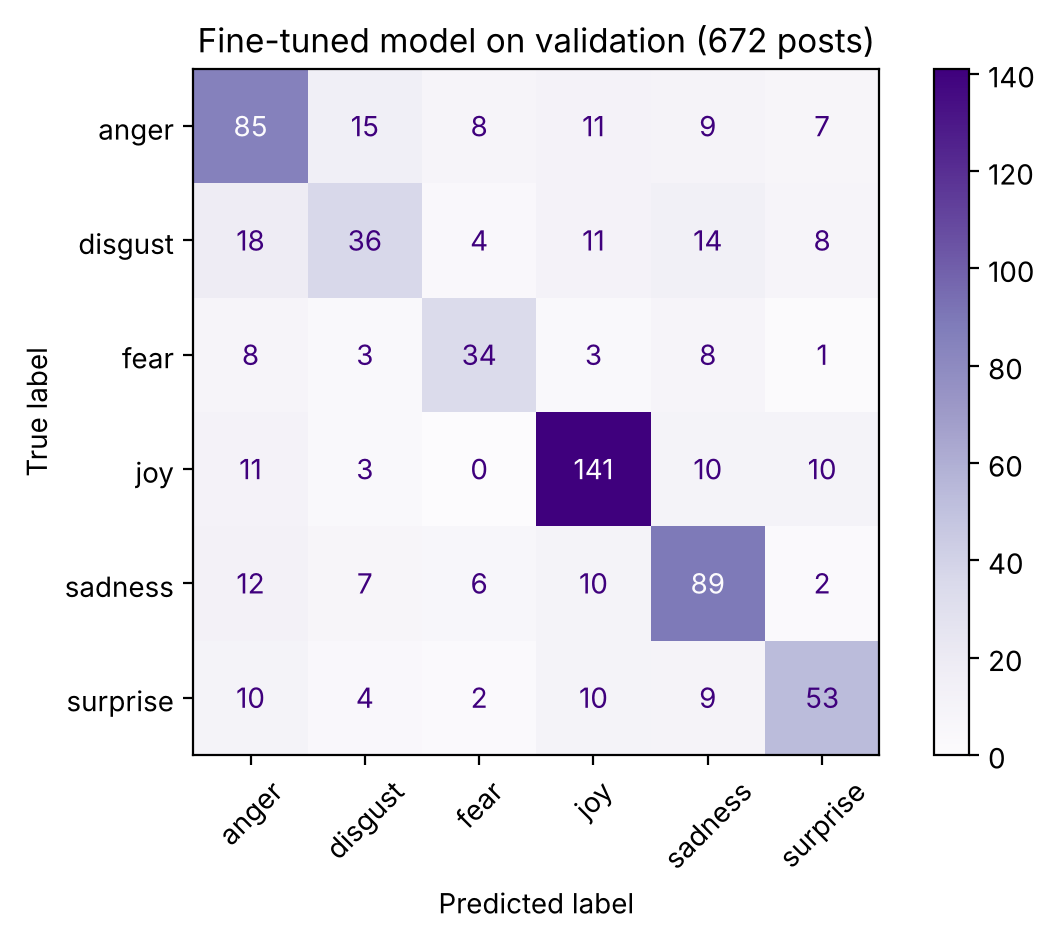

In [ ]:
# Where the final model still fails, on the validation posts.
print(classification_report(val_df["label"], ft_val_pred, labels=LABELS, digits=3))
ConfusionMatrixDisplay.from_predictions(val_df["label"], ft_val_pred, labels=LABELS, cmap="Purples", xticks_rotation=45)
plt.title("Fine-tuned model on validation (672 posts)"); plt.tight_layout(); plt.show()

## 4. Prediction and Submission

In [ ]:
# Retrain on ALL 3,360 training posts with the same settings (nothing is chosen any more),
# predict the 1,440 test posts, and write the file in sampleSubmission.csv's format.
t0 = time.time()
final_model = fine_tune(train_df)
print(f"final training took {(time.time() - t0) / 60:.1f} min")
test_df["label"] = np.array(LABELS)[emotion_scores(test_df["text"].tolist(), final_model).argmax(1)]

sample = pd.read_csv(f"{DATA}/sampleSubmission.csv")
submission = sample[["post_id"]].merge(test_df[["post_id", "label"]], on="post_id", how="left")
assert submission["label"].notna().all() and len(submission) == len(sample)
submission.to_csv("submission.csv", index=False)
print("submission.csv:", submission.shape)
print(submission["label"].value_counts().reindex(LABELS).to_dict())

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `7`.



Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 105/105 [00:00<00:00, 12523.87it/s]


[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                        | Status   |                                                                                       
---------------------------+----------+---------------------------------------------------------------------------------------
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([6])          
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 768]) vs model:torch.Size([6, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


final training took 12.0 min


submission.csv: (1440, 2)
{'anger': 335, 'disgust': 157, 'fear': 98, 'joy': 374, 'sadness': 278, 'surprise': 198}
